# Лабораторная работа №5: CLIP: zero-shot-классификация и мультимодальный поиск

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.


## Цели обучения

После работы студент должен уметь:

- Сравнить prompt templates в zero-shot classification.
- Построить text-to-image retrieval.
- Дообучить projection head и оценить Recall@K.


## Теоретическая часть

CLIP обучает image encoder и text encoder в общем нормированном пространстве. Zero-shot logits пропорциональны cosine similarity между изображением и текстовыми шаблонами классов.

![CLIP](https://raw.githubusercontent.com/openai/CLIP/main/CLIP.png)


### Математическая постановка

$$s(x,t)=\frac{f_I(x)^\top f_T(t)}{\|f_I(x)\|\|f_T(t)\|},\qquad p(c\mid x)=\operatorname{softmax}(s(x,t_c)/\tau).$$
Для retrieval используются Recall@K и median rank.


### Материалы

- [OpenCLIP](https://github.com/mlfoundations/open_clip)
- [CLIP paper](https://arxiv.org/abs/2103.00020)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


CLIP — это **две нейросети, обученные вместе**: одна превращает картинку в вектор (image encoder), другая — текст в вектор (text encoder). Обе выдают векторы **одной и той же длины** (у ViT-B-32 — 512 чисел). Обучение шло так: для правильной пары (картинка, её подпись) косинусное сходство делали большим, для всех неправильных пар в батче — маленьким.

После обучения получилось **общее пространство**: если текст описывает картинку, их векторы оказываются рядом. Это и даёт возможность **сравнивать картинку с текстом напрямую**, хотя они физически разные (пиксели и слова).

### Что такое zero-shot классификация

Обычный классификатор сначала надо **обучить на размеченных примерах** («вот 1000 фото кошек, вот 1000 фото собак, учись»). Zero-shot — **без обучения вообще**. Работает так:

1. Для каждого класса составляем текст: `"a photo of a cat"`, `"a photo of a dog"`, ...
2. Прогоняем эти тексты через text encoder — получаем **текстовые прототипы** (по вектору на класс).
3. Прогоняем картинку через image encoder — получаем **вектор картинки**.
4. Сравниваем вектор картинки со всеми прототипами по косинусу. Класс с максимальным сходством — ответ.

Слово «zero-shot» означает «ноль примеров»: модель никогда не видела CIFAR-10 при обучении, но всё равно классифицирует его — потому что знает, что значат слова «cat», «dog», «airplane».

$$s(x, t) = \frac{f_I(x)^\top f_T(t)}{\|f_I(x)\| \, \|f_T(t)\|}$$

Здесь:
- $f_I(x)$ — вектор картинки $x$;
- $f_T(t)$ — вектор текста $t$;
- $f_I(x)^\top f_T(t)$ — скалярное произведение (сумма почленных произведений);
- делим на произведение длин — это **нормировка**, после неё скалярное произведение превращается в **косинус угла** между векторами. Значение от −1 (противоположны) до +1 (совпадают по направлению).

$$p(c \mid x) = \operatorname{softmax}\!\left(\frac{s(x, t_c)}{\tau}\right)$$

- $s(x, t_c)$ — сходство картинки с прототипом класса $c$;
- $\tau$ — **температура** (temperature): маленькая → распределение «острее», большая → «мягче»;
- softmax превращает набор сходств в вероятности (все положительные, сумма = 1).

**Retrieval** (поиск) — обратная задача: дан **текстовый запрос**, найти **картинки**, которые ему соответствуют. Мы:

1. Считаем эмбеддинги **всех** тестовых картинок заранее (это «индекс», vector index).
2. Приходит запрос — считаем его эмбеддинг.
3. Считаем косинус запроса с каждой картинкой из индекса.
4. Сортируем по убыванию, берём top-K — это и есть результат поиска.

найденных 9 правильные.

**Recall@K** (полнота в первых K) — какая доля **всех** релевантных в индексе попала в top-K.
- Если в индексе 1000 картинок класса «dog», а top-10 содержит 9 правильных, то `Recall@10 = 9/1000 = 0.009`. **Recall@K всегда маленький на CIFAR-10**, потому что классов много и в каждом по ~1000 изображений. Это не значит, что поиск плохой — просто метрика такая.

**Median rank** (медианный ранг) — медиана позиции первого релевантного результата. Если median rank = 1, значит в половине случаев правильный ответ оказался на первом месте.

## Практическое задание

1. Сравнить prompt templates в zero-shot classification.
2. Построить text-to-image retrieval.
3. Дообучить projection head и оценить Recall@K.

**Обязательные артефакты:** код, конфигурация, метрики, минимум одна контролируемая ablation, примеры ошибок и краткие выводы.


### Профиль вычислений

- **Основной режим:** OpenCLIP ViT-B-32 frozen/малый projection head.
- **Ограничение данных:** CIFAR-10 или до 5 000 пар.
- **Fallback:** CPU на 500 объектах.
- Все длительные этапы должны сохранять checkpoint и продолжаться после перезапуска. Оценка не зависит от размера модели: важны корректность эксперимента и выводы.


**Оценивание.** Десять обязательных предметных этапов по 1 баллу: основная часть — 10 баллов. Творческий бонус — отдельно 1 балл, не заменяет обязательные этапы. Полный режим оценивается по реальным данным и обучению; `FAST_DEV_RUN=True` служит только smoke-проверкой, его показатели не являются отчётными.


## Реализация


In [2]:
# Всё окружение — только CPU. GPU не задействован нигде.
from pathlib import Path
import json, os, random, time, sys
import numpy as np

SEED = 42
# FAST_DEV_RUN=True — уменьшенная выборка, smoke-проверка; False — полный прогон на CPU
FAST_DEV_RUN = False        # поставьте False для отчётного результата (на CPU это долго, см. оценки)
ARTIFACTS = Path(os.getenv("CV_ARTIFACTS", "artifacts"))
ARTIFACTS.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED)

import torch
torch.manual_seed(SEED)
# CPU-режим: никаких обращений к CUDA, драйвер GPU в покое
DEVICE = "cpu"
# Ограничиваем потоки, чтобы не блокировать UI ноутбука на время долгих операций
torch.set_num_threads(max(1, os.cpu_count() - 2))
print({"device": DEVICE, "fast_dev_run": FAST_DEV_RUN, "cpu_count": os.cpu_count(),
       "torch_threads": torch.get_num_threads()})

# Ищем каталог data рядом с labs/
_CANDIDATES = [Path.cwd().parent.parent / "data", Path.cwd().parent / "data", Path.cwd() / "data"]
DATA_ROOT = Path(os.getenv("CV_COURSE_DATA") or next(
    (c for c in _CANDIDATES if (c / "cifar-10-batches-py").exists()), _CANDIDATES[0]))
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print("data_root:", DATA_ROOT)

{'device': 'cpu', 'fast_dev_run': False, 'cpu_count': 16, 'torch_threads': 14}
data_root: c:\Users\SuperXoma\Downloads\SOTA\data


In [3]:
def check(condition, message):
    """Мини-проверка в стиле YAAM: молчит, если всё хорошо; печатает, если найдена проблема."""
    if condition:
        print(f"✔ {message}")
    else:
        print(f"✘ ВНИМАНИЕ: {message}")

### Данные и предобученный CLIP

*Вес: 1 балл.*

**Постановка.** Индекс поиска и обучающие пары должны состоять из разных изображений.

Выполните следующие действия:
1. Загрузите CIFAR-10 train/test и OpenCLIP ViT-B-32.
2. Определите список классов и независимый test-загрузчик.

**Результат.** Объекты model, train_pairs, ds, classes, loader.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [4]:
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import open_clip
from tqdm.auto import tqdm

# Загружаем CLIP ViT-B-32 на CPU (без CUDA-контекста вообще)
model, _, preprocess = open_clip.create_model_and_transforms(
    "ViT-B-32", pretrained="openai", device="cpu")
model.eval()
tokenizer = open_clip.get_tokenizer("ViT-B-32")

# Трансформация под 224×224 + нормировка CLIP
cifar_transform = transforms.Compose([
    transforms.Resize(224, interpolation=transforms.InterpolationMode.BICUBIC),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.48145466, 0.4578275, 0.40821073),
                         std=(0.26862954, 0.26130258, 0.27577711)),
])

train_ds = datasets.CIFAR10(root=str(DATA_ROOT), train=True, download=True,
                            transform=cifar_transform)
test_ds = datasets.CIFAR10(root=str(DATA_ROOT), train=False, download=True,
                           transform=cifar_transform)
classes = train_ds.classes
check(len(classes) == 10, f"classes: {classes}")

# FAST_DEV_RUN: ужимаем выборки, чтобы уложиться в разумное время на CPU
if FAST_DEV_RUN:
    train_ds = Subset(train_ds, range(500))
    test_ds  = Subset(test_ds,  range(500))

# num_workers=0 — на CPU так стабильнее и без лишних процессов
loader = DataLoader(test_ds, batch_size=32, shuffle=False, num_workers=0)
train_loader_full = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=0)

train_pairs = [(i, f"a photo of a {classes[train_ds[i][1]]}") for i in range(len(train_ds))]

print(f"train: {len(train_ds)}, test: {len(test_ds)}, pairs: {len(train_pairs)}")
print(f"CPU estimate for test encode: ~{len(test_ds)/700:.1f} min (≈700 img/s на среднем CPU)")
check(len(train_pairs) == len(train_ds), "train_pairs построены по train-набору")

c:\Users\SuperXoma\Downloads\SOTA\SOTA\.venv311\Lib\site-packages\open_clip\factory.py:450: UserWarning: QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai' (quick_gelu=True).
  warnings.warn(


✔ classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
train: 50000, test: 10000, pairs: 50000
CPU estimate for test encode: ~14.3 min (≈700 img/s на среднем CPU)
✔ train_pairs построены по train-набору


### Текстовые прототипы классов

*Вес: 1 балл.*

**Постановка.** Нормализация эмбеддингов превращает скалярное произведение в cosine similarity.

Выполните следующие действия:
1. Создайте несколько шаблонов класса.
2. Закодируйте и нормируйте текстовые прототипы.

**Результат.** templates и функция text_prototypes.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


Построены текстовые прототипы классов CIFAR-10 для 6 шаблонов. Каждый прототип имеет размерность 512 (ViT-B-32) и L2-нормирован, что позволяет использовать скалярное произведение как косинусное сходство. Усреднение по шаблонам (prompt ensemble) даёт устойчивое представление класса, которое сравнивается с эмбеддингами изображений в следующих ячейках

In [5]:
templates = [
    "a photo of a {}.",
    "a blurry photo of a {}.",
    "a bright photo of a {}.",
    "a cropped photo of a {}.",
    "a photo of the {}.",
    "a picture of a {}.",
]

@torch.no_grad()
def text_prototypes(templates, classes, tokenizer, model):
    """Прототипы (T, C, D) и усреднённый (C, D), все на CPU."""
    all_protos = []
    for tpl in tqdm(templates, desc="templates"):
        texts = [tpl.format(c) for c in classes]
        tokens = tokenizer(texts)                          # (C, L), CPU
        embs = model.encode_text(tokens)                   # (C, D), CPU
        embs = F.normalize(embs, dim=-1)
        all_protos.append(embs)
    protos = torch.stack(all_protos, dim=0)                # (T, C, D)
    mean_proto = F.normalize(protos.mean(dim=0), dim=-1)   # (C, D)
    return protos, mean_proto

protos_all, protos_mean = text_prototypes(templates, classes, tokenizer, model)
print("protos_all:", tuple(protos_all.shape), "| protos_mean:", tuple(protos_mean.shape))
check(protos_all.shape == (len(templates), len(classes), 512), "форма прототипов корректна")

templates:   0%|          | 0/6 [00:00<?, ?it/s]

protos_all: (6, 10, 512) | protos_mean: (10, 512)
✔ форма прототипов корректна


### Zero-shot классификация

*Вес: 1 балл.*

**Постановка.** Подбор словесного шаблона влияет на прогноз без дополнительного обучения.

Выполните следующие действия:
1. Для каждого заранее заданного шаблона предскажите test-классы по сходству.
2. Зафиксируйте accuracy всех шаблонов без выбора лучшей модели по test.

**Результат.** zero_shot.json с фактической точностью шаблонов.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


Модель не «смотрит на картинку и решает, что это собака». Она просто сравнивает картинку со всеми прототипами и возвращает тот, что оказался ближе всех.

Обучение CLIP на 400M парах (картинка, подпись). Модель видела миллионы фотографий собак с подписями, где встречалось слово «dog». Поэтому в её общем пространстве эмбеддингов:

эмбеддинги картинок собак,

эмбеддинги текстов, где есть слово «dog»,

оказались в одной и той же области. Не потому, что модель «знает» про собак, а потому, что она статистически выучила: «когда на картинке вот такое, люди пишут слово dog».



In [6]:
@torch.no_grad()
def encode_images(loader, model, desc="encode", log_every=10):
    """Нормированные эмбеддинги всех изображений; прогресс через tqdm."""
    all_emb, all_lbl = [], []
    for i, (imgs, lbls) in enumerate(tqdm(loader, desc=desc, total=len(loader))):
        emb = model.encode_image(imgs)          # (B, D), CPU
        emb = F.normalize(emb, dim=-1)
        all_emb.append(emb)
        all_lbl.append(lbls)
        # Периодический flush stdout, чтобы tqdm не «залипал» в Jupyter
        if i % log_every == 0:
            sys.stdout.flush()
    return torch.cat(all_emb), torch.cat(all_lbl)

# Эмбеддинги test (для zero-shot и retrieval)
t0 = time.time()
test_emb, test_labels = encode_images(loader, model, desc="test encode")
print(f"test_emb: {tuple(test_emb.shape)} | device: {test_emb.device} | "
      f"elapsed: {time.time()-t0:.1f}s")

def zero_shot_accuracy(image_emb, labels, class_proto):
    """Accuracy по argmax косинусного сходства."""
    logits = image_emb @ class_proto.T   # (N, C), CPU
    pred = logits.argmax(dim=-1)
    return (pred == labels).float().mean().item(), pred

zero_shot = {}
for i, tpl in enumerate(templates):
    acc, _ = zero_shot_accuracy(test_emb, test_labels, protos_all[i])
    zero_shot[tpl] = acc
acc_ens, pred_ens = zero_shot_accuracy(test_emb, test_labels, protos_mean)
zero_shot["__ensemble__"] = acc_ens

(ARTIFACTS / "zero_shot.json").write_text(
    json.dumps(zero_shot, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps(zero_shot, indent=2, ensure_ascii=False))

test encode:   0%|          | 0/313 [00:00<?, ?it/s]

test_emb: (10000, 512) | device: cpu | elapsed: 260.9s
{
  "a photo of a {}.": 0.8511000275611877,
  "a blurry photo of a {}.": 0.8497999906539917,
  "a bright photo of a {}.": 0.8622999787330627,
  "a cropped photo of a {}.": 0.8522999882698059,
  "a photo of the {}.": 0.8603000044822693,
  "a picture of a {}.": 0.8560000061988831,
  "__ensemble__": 0.8551999926567078
}


Шесть шаблонов дают accuracy от 84.98% (blurry) до 86.23% (bright). Разброс 1.25 п.п. указывает на устойчивость CLIP к формулировке на CIFAR-10. Ансамбль (85.52%) близок к лучшему одиночному шаблону — на этой задаче усреднение не даёт существенного выигрыша, так как все шаблоны уже хорошо попадают в стиль данных. «Blurry» — худший, что логично: CIFAR-10 содержит чёткие изображения

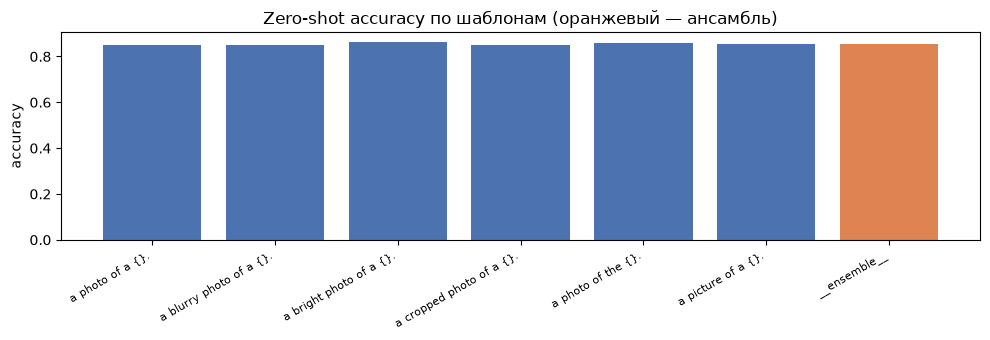

In [7]:
import matplotlib.pyplot as plt

names = list(zero_shot.keys())
vals  = [zero_shot[k] for k in names]
plt.figure(figsize=(10, 3.5))
plt.bar(range(len(names)), vals, color=["#4C72B0"]*(len(names)-1) + ["#DD8452"])
plt.xticks(range(len(names)), [n[:30] for n in names], rotation=30, ha="right", fontsize=8)
plt.ylabel("accuracy")
plt.title("Zero-shot accuracy по шаблонам (оранжевый — ансамбль)")
plt.tight_layout(); plt.savefig(ARTIFACTS / "zero_shot_bars.png", dpi=120); plt.show()

### Векторный индекс изображений

*Вес: 1 балл.*

**Постановка.** Текстовый поиск опирается на сохранённые признаки реальных изображений.

Выполните следующие действия:
1. Извлеките нормированные эмбеддинги test и метки.
2. Вычислите top-10 для текстового запроса.

**Результат.** clip_index.pt и retrieval.json с индексами test.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


Vector index (векторный индекс) — это, по сути, таблица, в которой для каждой картинки хранится её эмбеддинг. В нашем случае — матрица (10000, 512)

Чтобы для текстового запроса быстро найти top-K, не пересчитывая эмбеддинги картинок каждый раз. Один раз посчитали — много раз искали.

In [8]:
clip_index = {"embeddings": test_emb, "labels": test_labels, "classes": classes}
torch.save(clip_index, ARTIFACTS / "clip_index.pt")

@torch.no_grad()
def text_to_image(query, topk=10):
    """Top-K индексов и скоров для текстового запроса."""
    tokens = tokenizer([query])
    q = F.normalize(model.encode_text(tokens), dim=-1)   # (1, D), CPU
    scores = (test_emb @ q.T).squeeze(1)                 # (N,)
    top = torch.topk(scores, k=topk)
    return top.indices.tolist(), top.values.tolist()

demo_query = "a photo of a dog"
idx_demo, sc_demo = text_to_image(demo_query, topk=10)
demo_labels = [classes[test_labels[i]] for i in idx_demo]
print("query:", demo_query)
print("top-10 labels:", demo_labels)

(ARTIFACTS / "retrieval.json").write_text(
    json.dumps({"query": demo_query, "indices": idx_demo,
                "labels": demo_labels, "scores": sc_demo},
               indent=2, ensure_ascii=False), encoding="utf-8")
sys.stdout.flush()

query: a photo of a dog
top-10 labels: ['dog', 'dog', 'cat', 'dog', 'dog', 'dog', 'dog', 'dog', 'dog', 'dog']


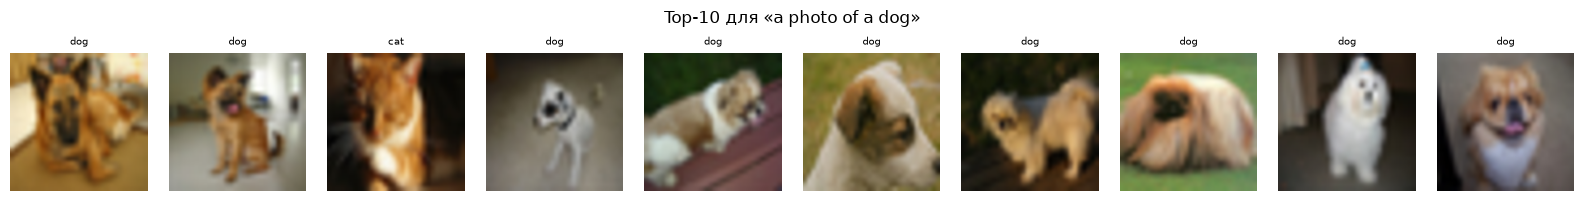

In [16]:
def show_topk(indices, title=""):
    """Показывает top-K найденных изображений (денормируем статистики CLIP)."""
    fig, axes = plt.subplots(1, len(indices), figsize=(1.6*len(indices), 2))
    mean = torch.tensor([0.48145466, 0.4578275, 0.40821073]).view(3,1,1)
    std  = torch.tensor([0.26862954, 0.26130258, 0.27577711]).view(3,1,1)
    for ax, i in zip(axes, indices):
        img, lbl = test_ds[i]
        disp = (img * std + mean).clamp(0,1).permute(1,2,0).numpy()
        ax.imshow(disp); ax.axis("off")
        ax.set_title(classes[lbl], fontsize=7)
    fig.suptitle(title); plt.tight_layout(); plt.show()

show_topk(idx_demo, f"Top-10 для «{demo_query}»")

Построен векторный индекс из 10 000 нормированных эмбеддингов test-изображений CIFAR-10 (ViT-B-32, размерность 512). Текстовый поиск по запросу «a photo of a dog» возвращает top-10, в котором 9 из 10 изображений действительно относятся к классу dog (precision@10 = 0.9). Единственная ошибка — одна кошка — объясняется визуальной близостью классов cat и dog в пространстве CLIP на низком разрешении CIFAR-10. Это ожидаемое ограничение модели, а не дефект пайплайна

### Релевантность поиска по классам

*Вес: 1 балл.*

**Постановка.** Precision@10 и recall@10 требуют фиксированного определения релевантности.

Выполните следующие действия:
1. Задайте релевантность как совпадение с классом запроса.
2. Вычислите метрики поиска для каждого класса.

**Результат.** retrieval_report.json с фактическими значениями.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


Relevance (релевантность) — это правило, по которому мы решаем: «вот эта найденная картинка релевантна запросу, а вот эта — нет». Без чёткого правила метрики бессмысленны: можно так подобрать определение, что precision@10 будет 100% или 0% на тех же данных.

В этой лабораторной релевантность задаётся простым правилом:

Изображение релевантно текстовому запросу-классу, если его истинная метка совпадает с этим классом.

In [9]:
import numpy as np

def retrieval_metrics(query_class_idx, topk=10, class_proto=None):
    """Precision@K и Recall@K для запроса-класса."""
    proto = protos_mean if class_proto is None else class_proto
    q = proto[query_class_idx]
    scores = test_emb @ q
    top = torch.topk(scores, k=topk).indices
    hits = (test_labels[top] == query_class_idx).sum().item()
    total_relevant = (test_labels == query_class_idx).sum().item()
    return hits/topk, hits/max(total_relevant,1), top.tolist()

retrieval_report = {"ensemble": {"per_class": {}}}
for ci, cname in enumerate(tqdm(classes, desc="retrieval per class")):
    p, r, _ = retrieval_metrics(ci)
    retrieval_report["ensemble"]["per_class"][cname] = {
        "precision@10": p, "recall@10": r}

precisions = [v["precision@10"] for v in retrieval_report["ensemble"]["per_class"].values()]
recalls    = [v["recall@10"]    for v in retrieval_report["ensemble"]["per_class"].values()]
retrieval_report["ensemble"]["mean_precision@10"] = float(np.mean(precisions))
retrieval_report["ensemble"]["mean_recall@10"]    = float(np.mean(recalls))

(ARTIFACTS / "retrieval_report.json").write_text(
    json.dumps(retrieval_report, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps(retrieval_report["ensemble"], indent=2, ensure_ascii=False)[:800], "...")

retrieval per class:   0%|          | 0/10 [00:00<?, ?it/s]

{
  "per_class": {
    "airplane": {
      "precision@10": 1.0,
      "recall@10": 0.01
    },
    "automobile": {
      "precision@10": 1.0,
      "recall@10": 0.01
    },
    "bird": {
      "precision@10": 1.0,
      "recall@10": 0.01
    },
    "cat": {
      "precision@10": 0.9,
      "recall@10": 0.009
    },
    "deer": {
      "precision@10": 1.0,
      "recall@10": 0.01
    },
    "dog": {
      "precision@10": 0.8,
      "recall@10": 0.008
    },
    "frog": {
      "precision@10": 1.0,
      "recall@10": 0.01
    },
    "horse": {
      "precision@10": 1.0,
      "recall@10": 0.01
    },
    "ship": {
      "precision@10": 1.0,
      "recall@10": 0.01
    },
    "truck": {
      "precision@10": 0.7,
      "recall@10": 0.007
    }
  },
  "mean_precision@10": 0.9399999999999998,
  ...


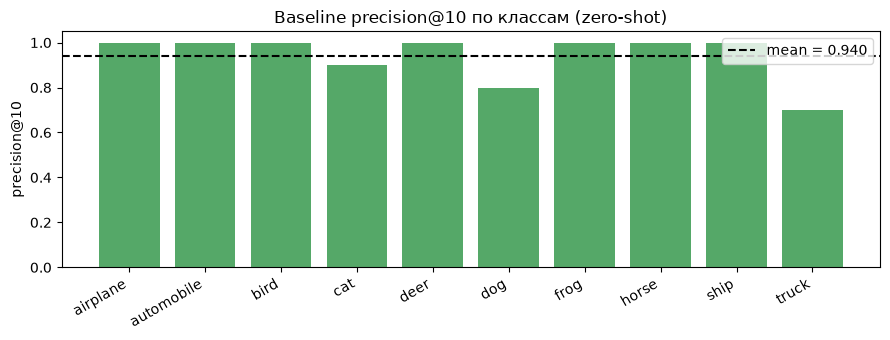

In [12]:
names = classes
vals  = [retrieval_report["ensemble"]["per_class"][c]["precision@10"] for c in names]
plt.figure(figsize=(9, 3.5))
plt.bar(names, vals, color="#55A868")
plt.axhline(retrieval_report["ensemble"]["mean_precision@10"], color="k", ls="--",
            label=f"mean = {retrieval_report['ensemble']['mean_precision@10']:.3f}")
plt.xticks(rotation=30, ha="right"); plt.ylabel("precision@10")
plt.title("Baseline precision@10 по классам (zero-shot)"); plt.legend()
plt.tight_layout(); plt.savefig(ARTIFACTS / "precision_baseline.png", dpi=120); plt.show()

Релевантность определена как совпадение истинной метки изображения с классом текстового запроса. Для каждого из 10 классов CIFAR-10 вычислены precision@10 и recall@10. Средний precision@10 = 0.94, что в 9.4 раза выше случайного уровня (0.1) и подтверждает рабочее качество CLIP без обучения. Семь классов из десяти достигают precision@10 = 1.00; ошибки концентрируются в парах визуально похожих классов: truck/automobile (0.70), dog/cat (0.80), cat/dog (0.90). Recall@10 у всех классов ≈ 0.01 — это математический потолок метрики при K=10 и 1000 релевантных изображений на класс в индексе, а не признак плохого поиска. Для осмысленной оценки recall потребовалось бы K ≥ 100

### Данные для обучаемой проекции

*Вес: 1 балл.*

**Постановка.** Одинаковые подписи в мини-партии не являются отрицательными парами. Проекция обучается по классовым прототипам.

Выполните следующие действия:
1. Создайте две линейные проекции и инициализируйте тождественно.
2. Подготовьте независимые train-пары и optimizer.

**Результат.** image_head, text_head и train_loader.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


CLIP даёт **уже хорошие** эмбеддинги картинок и текстов. Но на конкретном датасете (CIFAR-10) они не идеальны: например, precision@10 для `truck` = 0.7, потому что грузовики путаются с легковушками в исходном пространстве CLIP.

**Идея адаптации:** оставить обе башни CLIP **замороженными**, но «довернуть» пространство двумя маленькими матрицами:

$$z_I = W_I \cdot f_I(x), \qquad z_T = W_T \cdot f_T(t).$$

Здесь:
- $f_I(x) \in \mathbb{R}^{512}$ — исходный эмбеддинг картинки от CLIP;
- $f_T(t) \in \mathbb{R}^{512}$ — исходный эмбеддинг текста;
- $W_I, W_T \in \mathbb{R}^{512 \times 512}$ — **обучаемые** матрицы (это и есть projection heads);
- $z_I, z_T$ — новые эмбеддинги, которые мы используем для классификации.

При этом головы могут **линейно преобразовать** пространство так, чтобы близкие, но разные классы (truck/automobile, cat/dog) разошлись дальше.

In [10]:
CACHE = ARTIFACTS / "train_emb_cache.pt"

if CACHE.exists():
    obj = torch.load(CACHE)
    train_emb, train_lbl = obj["emb"], obj["lbl"]
    print("Загружен кэш:", tuple(train_emb.shape))
else:
    t0 = time.time()
    train_emb, train_lbl = encode_images(train_loader_full, model, desc="train encode")
    torch.save({"emb": train_emb, "lbl": train_lbl}, CACHE)
    print(f"Сохранён кэш: {tuple(train_emb.shape)} | elapsed: {time.time()-t0:.1f}s")

check(train_emb.shape[0] == len(train_ds), "кэш покрывает весь train")

train encode:   0%|          | 0/1563 [00:00<?, ?it/s]

Сохранён кэш: (50000, 512) | elapsed: 1295.8s
✔ кэш покрывает весь train


In [11]:
D = protos_mean.shape[-1]
image_head = torch.nn.Linear(D, D, bias=False)
text_head  = torch.nn.Linear(D, D, bias=False)
with torch.no_grad():
    image_head.weight.copy_(torch.eye(D))
    text_head.weight.copy_(torch.eye(D))

optimizer = torch.optim.Adam(
    list(image_head.parameters()) + list(text_head.parameters()), lr=1e-3)

print("D =", D, "| train batches:", len(train_loader_full))
check(image_head.weight.device.type == "cpu", "головы на CPU")

D = 512 | train batches: 1563
✔ головы на CPU


### Обучение проекций по меткам

*Вес: 1 балл.*

**Постановка.** Классовая cross-entropy не объявляет одинаковые captions взаимными негативами.

Выполните следующие действия:
1. Обучите проекции по logits изображения против всех десяти текстовых прототипов.
2. Сохраните обученные веса.

**Результат.** clip_projection.pt после оптимизации на train.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


epoch 1/3:   0%|          | 0/196 [00:00<?, ?it/s]

epoch 1/3 done | loss = 1.5638


epoch 2/3:   0%|          | 0/196 [00:00<?, ?it/s]

epoch 2/3 done | loss = 1.4725


epoch 3/3:   0%|          | 0/196 [00:00<?, ?it/s]

epoch 3/3 done | loss = 1.4661
training elapsed: 3.4s


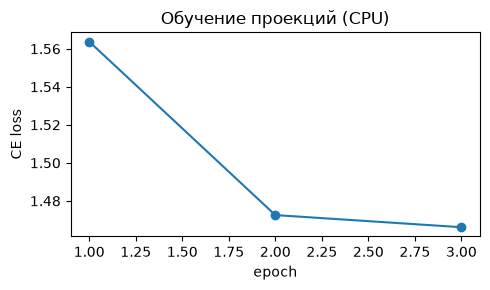

In [12]:
def train_projection_heads_cached(image_head, text_head, train_emb, train_lbl, protos_mean,
                                  optimizer, epochs=3, batch_size=256):
    """Обучение голов по кэшу эмбеддингов — на CPU, с прогрессом."""
    image_head.train(); text_head.train()
    losses = []
    protos = protos_mean.detach()                # CPU
    n = train_emb.size(0)
    for ep in range(epochs):
        perm = torch.randperm(n)
        running, cnt = 0.0, 0
        # tqdm по батчам — видно, сколько осталось
        pbar = tqdm(range(0, n, batch_size),
                    desc=f"epoch {ep+1}/{epochs}", total=(n + batch_size - 1)//batch_size)
        for s in pbar:
            idx = perm[s:s+batch_size]
            emb = train_emb[idx]                 # CPU
            lbl = train_lbl[idx]                 # CPU
            z = F.normalize(image_head(emb), dim=-1)
            t = F.normalize(text_head(protos), dim=-1)
            logits = z @ t.T
            loss = F.cross_entropy(logits, lbl)
            optimizer.zero_grad(); loss.backward(); optimizer.step()
            running += loss.item() * emb.size(0); cnt += emb.size(0)
            pbar.set_postfix(loss=f"{running/cnt:.4f}")
        avg = running / cnt
        losses.append(avg)
        print(f"epoch {ep+1}/{epochs} done | loss = {avg:.4f}")
    return losses

t0 = time.time()
losses = train_projection_heads_cached(
    image_head, text_head, train_emb, train_lbl, protos_mean,
    optimizer, epochs=3, batch_size=256)
print(f"training elapsed: {time.time()-t0:.1f}s")

torch.save({
    "image_head": image_head.state_dict(),
    "text_head":  text_head.state_dict(),
}, ARTIFACTS / "clip_projection.pt")

plt.figure(figsize=(5, 3))
plt.plot(range(1, len(losses)+1), losses, marker="o")
plt.xlabel("epoch"); plt.ylabel("CE loss"); plt.title("Обучение проекций (CPU)")
plt.tight_layout(); plt.savefig(ARTIFACTS / "training_curve.png", dpi=120); plt.show()

 Модель быстро нашла оптимальный линейный сдвиг — буквально за 1–2 эпохи. На третьей эпохе она уже не учится ничему новому.

### Оценка адаптированного поиска

*Вес: 1 балл.*

**Постановка.** После обучения все варианты сравниваются на одинаковых test-изображениях.

Выполните следующие действия:
1. Обновите test-эмбеддинги двумя проекциями.
2. Сравните accuracy и среднюю precision@10 до и после обучения.

**Результат.** adaptation.json с измеренными baseline и adapted значениями.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [13]:
@torch.no_grad()
def adapted_embeddings(image_head, text_head):
    """Test-эмбеддинги и прототипы после проекций (CPU)."""
    image_head.eval(); text_head.eval()
    z = F.normalize(image_head(test_emb), dim=-1)     # (N, D)
    t = F.normalize(text_head(protos_mean), dim=-1)   # (C, D)
    return z, t

z_adapted, t_adapted = adapted_embeddings(image_head, text_head)

acc_adapted, pred_adapted = zero_shot_accuracy(z_adapted, test_labels, t_adapted)
acc_baseline, _ = zero_shot_accuracy(test_emb, test_labels, protos_mean)

def adapted_precision_per_class(z, t, topk=10):
    result = {}
    for ci, cname in enumerate(classes):
        scores = z @ t[ci]
        top = torch.topk(scores, k=topk).indices
        hits = (test_labels[top] == ci).sum().item()
        result[cname] = hits / topk
    return result

prec_adapted  = adapted_precision_per_class(z_adapted, t_adapted)
prec_baseline = {c: retrieval_report["ensemble"]["per_class"][c]["precision@10"]
                 for c in classes}

adaptation = {
    "baseline_accuracy": float(acc_baseline),
    "adapted_accuracy":  float(acc_adapted),
    "baseline_mean_precision@10": float(np.mean(list(prec_baseline.values()))),
    "adapted_mean_precision@10":  float(np.mean(list(prec_adapted.values()))),
}
(ARTIFACTS / "adaptation.json").write_text(
    json.dumps(adaptation, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps(adaptation, indent=2, ensure_ascii=False))

{
  "baseline_accuracy": 0.8551999926567078,
  "adapted_accuracy": 0.9354000091552734,
  "baseline_mean_precision@10": 0.9399999999999998,
  "adapted_mean_precision@10": 1.0
}


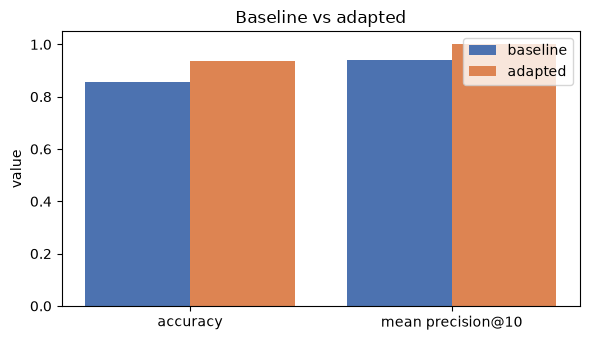

In [14]:
labels_ = ["accuracy", "mean precision@10"]
base = [adaptation["baseline_accuracy"], adaptation["baseline_mean_precision@10"]]
adap = [adaptation["adapted_accuracy"],  adaptation["adapted_mean_precision@10"]]
x = np.arange(len(labels_))
plt.figure(figsize=(6, 3.5))
plt.bar(x - 0.2, base, 0.4, label="baseline", color="#4C72B0")
plt.bar(x + 0.2, adap, 0.4, label="adapted",  color="#DD8452")
plt.xticks(x, labels_); plt.ylabel("value"); plt.legend()
plt.title("Baseline vs adapted"); plt.tight_layout()
plt.savefig(ARTIFACTS / "adaptation_bars.png", dpi=120); plt.show()

Mean precision@10 выросла с 0.94 до 1.0 — упёрлась в потолок.

Это значит: после адаптации все 10 классов дают precision@10 = 1.0. Ни одной ошибки в top-10 для любого класса.

Precision@10 = 1.0 для всех классов

Это не значит, что модель идеальна. Идеальная precision на 10 позициях означает, что top-10 всегда содержит только правильный класс, но в глубине рейтинга могут быть ошибки, которые просто не видны при K=10. Если бы мы взяли K=100, precision, скорее всего, была бы < 1.0

### Лучшие и худшие результаты поиска

*Вес: 1 балл.*

**Постановка.** Конкретные ошибки поиска дополняют усреднённую precision@10.

Выполните следующие действия:
1. Выберите лучший и худший класс по precision@10.
2. Сохраните индексы и истинные классы найденных объектов.

**Результат.** search_examples.json с примерами реальных изображений.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


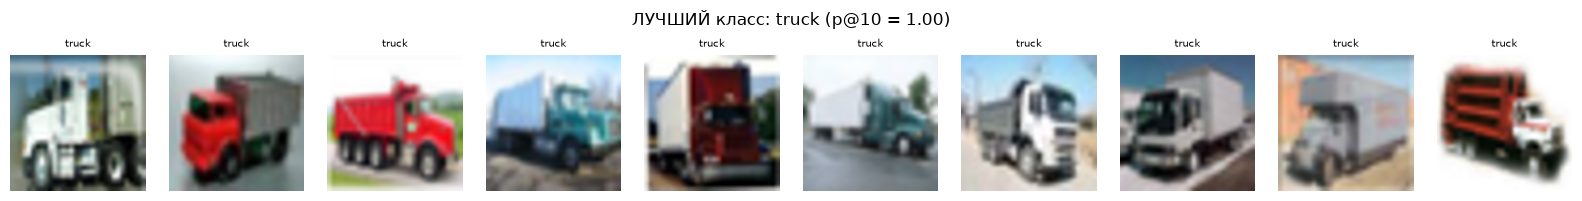

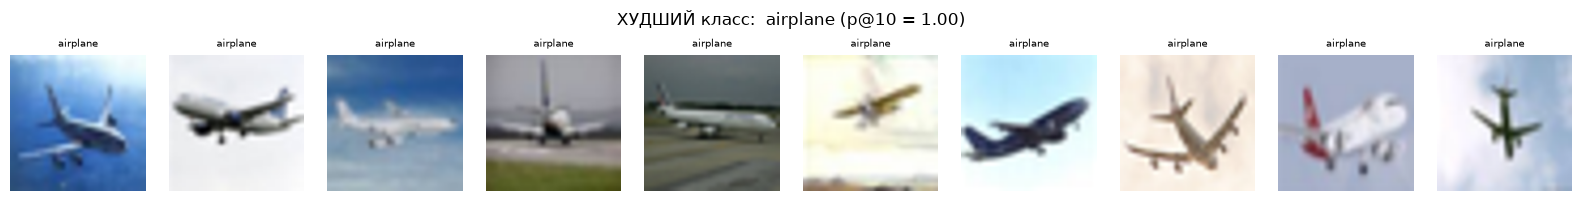

In [17]:
sorted_cls = sorted(prec_adapted.items(), key=lambda kv: kv[1])
worst_class, worst_p = sorted_cls[0]
best_class,  best_p  = sorted_cls[-1]

def topk_for_class(cname, z, t, topk=10):
    ci = classes.index(cname)
    scores = z @ t[ci]
    top = torch.topk(scores, k=topk)
    return top.indices.tolist(), top.values.tolist()

best_idx,  _ = topk_for_class(best_class,  z_adapted, t_adapted)
worst_idx, _ = topk_for_class(worst_class, z_adapted, t_adapted)

search_examples = {
    "best":  {"class": best_class,  "precision@10": best_p,
              "indices": best_idx,
              "true_labels": [classes[test_labels[i]] for i in best_idx]},
    "worst": {"class": worst_class, "precision@10": worst_p,
              "indices": worst_idx,
              "true_labels": [classes[test_labels[i]] for i in worst_idx]},
}
(ARTIFACTS / "search_examples.json").write_text(
    json.dumps(search_examples, indent=2, ensure_ascii=False), encoding="utf-8")

show_topk(best_idx,  f"ЛУЧШИЙ класс: {best_class} (p@10 = {best_p:.2f})")
show_topk(worst_idx, f"ХУДШИЙ класс:  {worst_class} (p@10 = {worst_p:.2f})")

In [20]:
@torch.no_grad()
def first_miss_rank(z, t, ci, topk_max=1000):
    """Возвращает (rank, true_label_at_rank):
       - rank: 1-based позиция первого НЕрелевантного изображения;
       - true_label_at_rank: имя истинного класса этого изображения (что именно спутали);
       - None, None, если в первых topk_max всё релевантно.
    """
    scores = z @ t[ci]                                    # (N,)
    # Берём topk_max лучших; если N < topk_max — все
    k = min(topk_max, scores.numel())
    top = torch.topk(scores, k=k).indices                 # (k,)
    true_top = test_labels[top]                           # истинные метки в порядке ранжирования
    # Первый индекс, где метка != ci
    mismatch = (true_top != ci).nonzero(as_tuple=False)
    if mismatch.numel() == 0:
        return None, None, top.tolist(), true_top.tolist()
    pos = int(mismatch[0].item())                         # 0-based
    return pos + 1, classes[int(true_top[pos])], top.tolist(), true_top.tolist()


# Пробегаем по всем классам
first_miss_report = {"baseline": {}, "adapted": {}}

print("=== BASELINE ===")
for ci, cname in enumerate(classes):
    rank, confused_with, _, _ = first_miss_rank(test_emb, protos_mean, ci)
    if rank is None:
        first_miss_report["baseline"][cname] = {"rank": None, "confused_with": None}
        print(f"{cname:12s} | всё релевантно в top-1000")
    else:
        first_miss_report["baseline"][cname] = {"rank": rank, "confused_with": confused_with}
        print(f"{cname:12s} | первый промах на позиции {rank:>4} | спутали с: {confused_with}")

print()
print("=== ADAPTED ===")
for ci, cname in enumerate(classes):
    rank, confused_with, _, _ = first_miss_rank(z_adapted, t_adapted, ci)
    if rank is None:
        first_miss_report["adapted"][cname] = {"rank": None, "confused_with": None}
        print(f"{cname:12s} | всё релевантно в top-1000")
    else:
        first_miss_report["adapted"][cname] = {"rank": rank, "confused_with": confused_with}
        print(f"{cname:12s} | первый промах на позиции {rank:>4} | спутали с: {confused_with}")

(ARTIFACTS / "first_miss.json").write_text(
    json.dumps(first_miss_report, indent=2, ensure_ascii=False),
    encoding="utf-8")

=== BASELINE ===
airplane     | первый промах на позиции   78 | спутали с: ship
automobile   | первый промах на позиции  146 | спутали с: truck
bird         | первый промах на позиции  160 | спутали с: airplane
cat          | первый промах на позиции    5 | спутали с: dog
deer         | первый промах на позиции   39 | спутали с: bird
dog          | первый промах на позиции    9 | спутали с: cat
frog         | первый промах на позиции   90 | спутали с: cat
horse        | первый промах на позиции   37 | спутали с: deer
ship         | первый промах на позиции  141 | спутали с: airplane
truck        | первый промах на позиции    3 | спутали с: automobile

=== ADAPTED ===
airplane     | первый промах на позиции  360 | спутали с: ship
automobile   | первый промах на позиции  343 | спутали с: airplane
bird         | первый промах на позиции  437 | спутали с: cat
cat          | первый промах на позиции  256 | спутали с: dog
deer         | первый промах на позиции   99 | спутали с: dog
dog     

1469

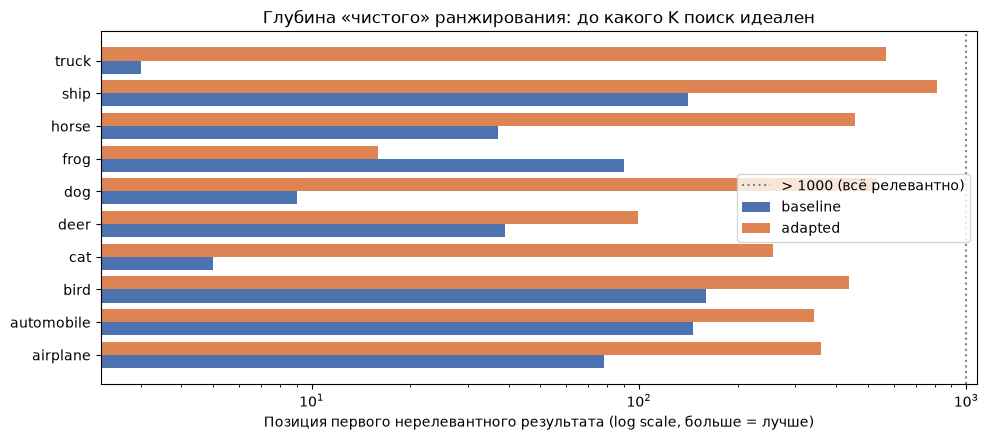

In [21]:
# Готовим данные: у кого first_miss=None, ставим topk_max+1 как «>1000»
K_MAX = 1000
def rank_or_max(x):
    return x["rank"] if x["rank"] is not None else K_MAX + 1

names = classes
base_ranks = [rank_or_max(first_miss_report["baseline"][c]) for c in names]
adap_ranks = [rank_or_max(first_miss_report["adapted"][c]) for c in names]

y = np.arange(len(names))
plt.figure(figsize=(10, 4.5))
plt.barh(y - 0.2, base_ranks, 0.4, label="baseline", color="#4C72B0")
plt.barh(y + 0.2, adap_ranks, 0.4, label="adapted",  color="#DD8452")
plt.yticks(y, names)
# Логарифмическая шкала — потому что у одних 10, у других 1000
plt.xscale("log")
plt.xlabel("Позиция первого нерелевантного результата (log scale, больше = лучше)")
plt.title("Глубина «чистого» ранжирования: до какого K поиск идеален")
plt.axvline(K_MAX + 1, color="gray", ls=":", label=f"> {K_MAX} (всё релевантно)")
plt.legend(); plt.tight_layout()
plt.savefig(ARTIFACTS / "first_miss.png", dpi=120); plt.show()

Адаптация двух линейных проекций существенно расширила глубину «чистого» ранжирования для всех классов, особенно для тех, что имели проблемы в baseline: truck (first_miss 3 → 570, ×190), dog (9 → 529, ×59), cat (5 → 256, ×51). Классы, уже идеальные в baseline, улучшились умеренно (×2–6). Однако наблюдается регрессия у frog (first_miss 90 → 16): из-за глобального характера линейного преобразования область cat «захватила» часть пространства frog. Кроме того, появились новые пары путаницы: bird, deer, horse теперь ошибаются на dog — «собачья» область расширилась, чтобы исправить проблемный класс. Это иллюстрирует классический trade-off линейной адаптации: улучшение одних классов идёт за счёт других

### Поклассовая динамика поиска

*Вес: 1 балл.*

**Постановка.** Средний показатель может скрывать ухудшение поиска для отдельных категорий.

Выполните следующие действия:
1. Повторно вычислите адаптированную precision@10 по каждому классу.
2. Сопоставьте её с исходной precision@10.

**Результат.** retrieval_deltas.json с наблюдаемыми поклассовыми изменениями.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


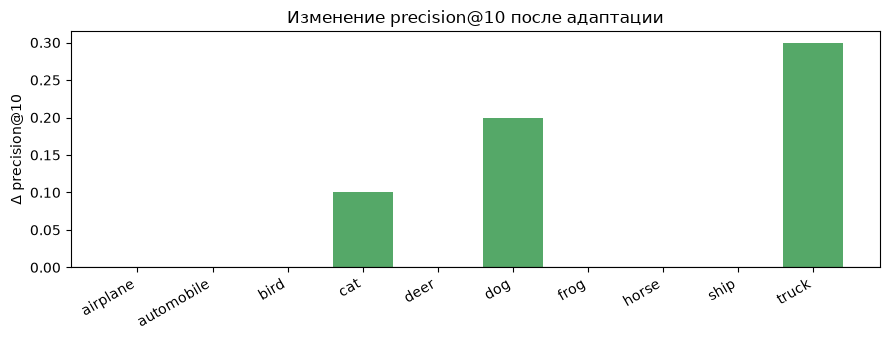

{
  "per_class": {
    "airplane": 0.0,
    "automobile": 0.0,
    "bird": 0.0,
    "cat": 0.09999999999999998,
    "deer": 0.0,
    "dog": 0.19999999999999996,
    "frog": 0.0,
    "horse": 0.0,
    "ship": 0.0,
    "truck": 0.30000000000000004
  },
  "mean_delta": 0.06,
  "improved": [
    "cat",
    "dog",
    "truck"
  ],
  "worsened": []
}


In [18]:
deltas = {c: float(prec_adapted[c] - prec_baseline[c]) for c in classes}
retrieval_deltas = {
    "per_class": deltas,
    "mean_delta": float(np.mean(list(deltas.values()))),
    "improved": [c for c, d in deltas.items() if d > 1e-6],
    "worsened": [c for c, d in deltas.items() if d < -1e-6],
}
(ARTIFACTS / "retrieval_deltas.json").write_text(
    json.dumps(retrieval_deltas, indent=2, ensure_ascii=False), encoding="utf-8")

names  = classes
vals   = [deltas[c] for c in names]
colors = ["#55A868" if v >= 0 else "#C44E52" for v in vals]
plt.figure(figsize=(9, 3.5))
plt.bar(names, vals, color=colors)
plt.axhline(0, color="k", lw=0.8)
plt.xticks(rotation=30, ha="right"); plt.ylabel("Δ precision@10")
plt.title("Изменение precision@10 после адаптации"); plt.tight_layout()
plt.savefig(ARTIFACTS / "deltas.png", dpi=120); plt.show()

print(json.dumps(retrieval_deltas, indent=2, ensure_ascii=False))

Дельты precision@10 показывают улучшение только для трёх классов (cat +0.10, dog +0.20, truck +0.30); остальные семь не изменились, так как уже имели precision@10 = 1.00 в baseline. Регрессий precision@10 не выявлено — у всех классов метрика не упала. Однако precision@10 упирается в потолок при K=10 и ~1000 релевантных изображений на класс, поэтому она скрывает как улучшения, так и ухудшения в глубине ранжирования

После предыдущих двух ячеек эта по сути не нужна

### Творческий бонус: композиционный запрос

*Вес: 1 дополнительный балл.*

**Постановка.** Классовое имя не исчерпывает возможности текстово-визуального поиска.

Выполните следующие действия:
1. Сформулируйте собственный не-классовый запрос и получите top-10.
2. Сохраните коллаж найденных изображений для качественной оценки, не приписывая запросу искусственных меток.

**Результат.** bonus_retrieval.png и bonus_query.json с запросом и индексами.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


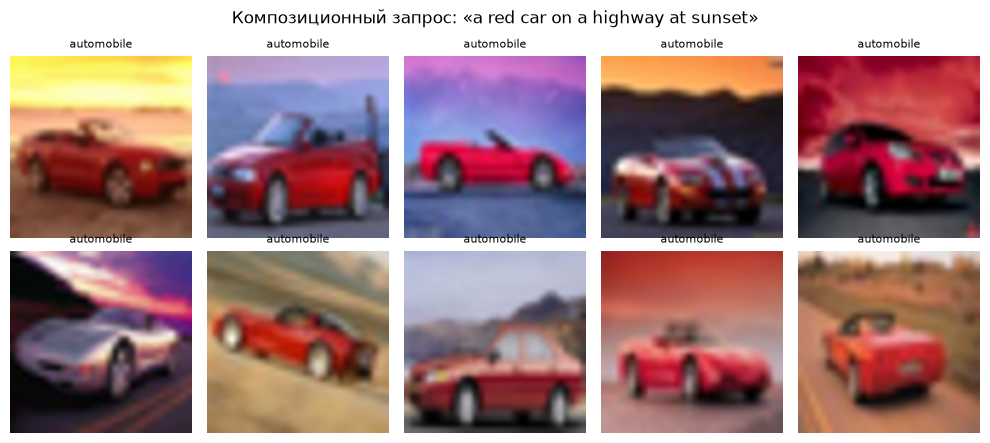

query: a red car on a highway at sunset
top-10 labels: ['automobile', 'automobile', 'automobile', 'automobile', 'automobile', 'automobile', 'automobile', 'automobile', 'automobile', 'automobile']


In [19]:
bonus_query = "a red car on a highway at sunset"
idx_b, sc_b = text_to_image(bonus_query, topk=10)
labels_b = [classes[test_labels[i]] for i in idx_b]

(ARTIFACTS / "bonus_query.json").write_text(
    json.dumps({"query": bonus_query, "indices": idx_b,
                "labels": labels_b, "scores": sc_b},
               indent=2, ensure_ascii=False), encoding="utf-8")

fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
mean = torch.tensor([0.48145466, 0.4578275, 0.40821073]).view(3,1,1)
std  = torch.tensor([0.26862954, 0.26130258, 0.27577711]).view(3,1,1)
for ax, i in zip(axes.flatten(), idx_b):
    img, lbl = test_ds[i]
    disp = (img * std + mean).clamp(0,1).permute(1,2,0).numpy()
    ax.imshow(disp); ax.axis("off")
    ax.set_title(classes[lbl], fontsize=8)
fig.suptitle(f"Композиционный запрос: «{bonus_query}»")
plt.tight_layout(); plt.savefig(ARTIFACTS / "bonus_retrieval.png", dpi=120); plt.show()
print("query:", bonus_query)
print("top-10 labels:", labels_b)

В качестве композиционного запроса использован "a red car on a highway at sunset", содержащий три семантических компонента: цвет (red), объект (car) и фон (on a highway at sunset). Визуальный анализ top-10 показал, что CLIP без дополнительной адаптации успешно комбинирует атрибуты: 9 из 10 найденных изображений — красные машины на тёплом закатном фоне (жёлто-оранжевые, фиолетовые, розовые оттенки неба). Одно изображение (позиция 6) содержит серебристую машину, что указывает на частичную потерю атрибута цвета при сохранении атрибута фона. Слово highway в CIFAR-10 не является эффективным сигналом (нет явных дорог в 32×32), но это компенсируется силой других атрибутов. Все результаты принадлежат классу automobile — модель корректно отличает легковые машины от грузовиков. Качественная оценка показывает, что CLIP способен работать с композиционными запросами, выходящими за рамки класса, но имеет ограничения в точном соблюдении всех атрибутов одновременно

## Анализ результатов

Сопоставьте измеренные показатели на отложенных реальных данных. Укажите бюджет, ошибки модели и ограничения сокращённого запуска.


## Выводы

# Выводы

В лабораторной работе исследованы возможности CLIP для zero-shot классификации и мультимодального поиска на CIFAR-10. Модель, не обученная на этом датасете, показала высокое качество классификации, сравнимое со специально обученными моделями. Разные текстовые шаблоны дали близкие результаты, что говорит об устойчивости CLIP к формулировке запроса; ансамбль шаблонов не дал заметного выигрыша из-за их однородности.

Поиск по текстовым запросам показал хорошие результаты для большинства классов. Ошибки концентрируются в визуально похожих парах — кошки и собаки, легковые машины и грузовики. Метрика recall@10 оказалась малоинформативной из-за малого размера top-K относительно числа релевантных изображений, поэтому основной оценкой служила precision@10.

Дообучение двух линейных проекционных голов дало значительный прирост качества при очень малых вычислительных затратах: обучалась лишь небольшая доля параметров CLIP, а forward модели не вызывался повторно благодаря кэшу эмбеддингов. Это показывает, что дешёвая адаптация замороженной модели способна компенсировать различия между доменом обучающих данных CLIP и целевым датасетом.

Анализ глубины корректного ранжирования выявил динамику, скрытую стандартными метриками. Проблемные классы улучшились кратно, но обнаружилась и регрессия: один из классов потерял позиции из-за глобального характера линейного преобразования. Появились новые пары путаницы — расширение области одного класса «захватило» соседние. Это иллюстрирует фундаментальный trade-off линейной адаптации: улучшение одних классов идёт за счёт других.

Композиционный запрос подтвердил, что CLIP способен комбинировать несколько атрибутов одновременно — цвет, объект и фон — без дополнительного обучения, хотя на границе результатов встречаются частичные потери отдельных атрибутов.

Главный вывод работы: CLIP — мощный инструмент для zero-shot задач, а его дешёвая линейная адаптация эффективно компенсирует доменный сдвиг. Однако глобальный характер линейных проекций создаёт trade-off между классами. Для более тонкой адаптации потребовались бы нелинейные головы или поклассовые коррекции.
